# MATH 4432 – Assignment 1

**Due:** 11:59 p.m. September 30, 2026 (Canvas)

Submission:
1. A `.pdf` with all conceptual parts (Ch. 2: 1, 3; Ch. 3: 1, 5).
2. An `.html` generated from this notebook with all code and results (Ch. 2: 8, 10; Ch. 3: 8, 9; bias-variance task).

Generate the HTML with

```
jupyter nbconvert --to html --execute MATH4432_Assignment1.ipynb
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from ISLP import load_data

%matplotlib inline
plt.rcParams["figure.dpi"] = 100

## Coding task: bias-variance trade-off

Ground truth
$$ y = \sin(2 x_1), $$
with $n_{\text{train}} = 50$ training samples, noise $\mathcal{N}(0, 0.5^2)$ and $n_{\text{test}} = 500$ test samples.
Of the $p$ predictors only $x_1$ is related to $y$; $x_2, \dots, x_p$ are pure noise.

We compare linear regression and KNN regression ($k = 1, \dots, 9$) for $p \in \{1, 2, 3, 4, 10, 20\}$.
For every $p$ the training response is re-drawn `nrep = 100` times (fixed $X$), so that for each test point $x_0$ we can estimate

- $\bar f(x_0) = \mathbb{E}[\hat f(x_0)]$ as the average prediction over repetitions,
- $\text{Bias}^2 = \mathbb{E}_{x_0}\big[(f(x_0) - \bar f(x_0))^2\big]$,
- $\text{Var} = \mathbb{E}_{x_0}\,\mathbb{E}\big[(\hat f(x_0) - \bar f(x_0))^2\big]$,
- $\text{MSE} = \text{Bias}^2 + \text{Var}$ (the irreducible error $\sigma^2 = 0.25$ is left out since the test targets are noise-free).

The expected pattern of the MSE is that of FIGURE 3.20 (p. 115) in the reference book.

In [2]:
np.random.seed(4423)

ntrain = 50            # Training
ntest = 500            # Test
nrep = 100             # Repeat 100 times
p = 20
puse = np.array([1, 2, 3, 4, 10, 20])   # Number of predictors
k = np.arange(1, 10)
sigma = 0.5

Xtrain = np.random.uniform(-1, 1, [ntrain, p])
Xtest = np.random.uniform(-1, 1, [ntest, p])
y0 = np.sin(2 * Xtrain[:, 0])          # Only the first predictor is related to y
ytest = np.sin(2 * Xtest[:, 0])

out_knn = pd.DataFrame()               # Output results
out_lm = pd.DataFrame()

for i in range(len(puse)):
    Xtr = Xtrain[:, :puse[i]]          # use the first puse[i] predictors
    Xte = Xtest[:, :puse[i]]
    yhat_lm = np.zeros((ntest, nrep))
    yhat_knn = np.zeros((ntest, nrep, len(k)))

    for l in range(nrep):
        y = y0 + np.random.normal(0, sigma, ntrain)

        # Fit linear regression, predicted values on the test set
        fit_lm = LinearRegression().fit(Xtr, y)
        yhat_lm[:, l] = fit_lm.predict(Xte)

        for j in range(len(k)):
            # Fit KNN with k[j] neighbours, predicted values on the test set
            fit_knn = KNeighborsRegressor(n_neighbors=k[j]).fit(Xtr, y)
            yhat_knn[:, l, j] = fit_knn.predict(Xte)

    print(f"p = {puse[i]:2d}: {nrep} repetitions finished.")

    # Bias and variance of linear regression
    ybar_lm = yhat_lm.mean(axis=1)                              # E(f^hat), one value per test point
    biasSQ_lm = np.mean((ytest - ybar_lm) ** 2)                 # E[ (f - E(f^hat))^2 ]
    variance_lm = np.mean((yhat_lm - ybar_lm[:, None]) ** 2)    # E[ (E(f^hat) - f^hat)^2 ]
    err_lm = biasSQ_lm + variance_lm                            # total MSE
    out_lm = pd.concat([out_lm, pd.DataFrame({'biasSQ_lm': [biasSQ_lm], 'variance_lm': [variance_lm],
                                              'MSE': [err_lm], 'p': [puse[i]]})])

    # Bias and variance of KNN regression
    for j in range(len(k)):
        ybar_knn = yhat_knn[:, :, j].mean(axis=1)                              # E(f^hat)
        biasSQ_knn = np.mean((ytest - ybar_knn) ** 2)                          # E[ (f - E(f^hat))^2 ]
        variance_knn = np.mean((yhat_knn[:, :, j] - ybar_knn[:, None]) ** 2)   # E[ (E(f^hat) - f^hat)^2 ]
        err_knn = biasSQ_knn + variance_knn                                    # total MSE
        out_knn = pd.concat([out_knn, pd.DataFrame({'biasSQ_knn': [biasSQ_knn], 'variance_knn': [variance_knn],
                                                    'MSE': [err_knn], '1/K': [1 / k[j]], 'p': [puse[i]]})])

out_lm = out_lm.reset_index(drop=True)
out_knn = out_knn.reset_index(drop=True)

p =  1: 100 repetitions finished.


p =  2: 100 repetitions finished.


p =  3: 100 repetitions finished.


p =  4: 100 repetitions finished.


p = 10: 100 repetitions finished.


p = 20: 100 repetitions finished.


### Results: linear regression

In [3]:
out_lm.round(4)

,biasSQ_lm,variance_lm,MSE,p
0,0.0262,0.0097,0.0359,1
1,0.0268,0.0148,0.0417,2
2,0.0301,0.0203,0.0504,3
3,0.0319,0.0279,0.0599,4
4,0.0326,0.0615,0.0941,10
5,0.0405,0.1842,0.2247,20


### Results: KNN regression

In [4]:
out_knn.pivot(index='1/K', columns='p', values='MSE').sort_index().round(4)

p,1,2,3,4,10,20
1/K,,,,,,
0.111111,0.0310,0.0712,0.1226,0.1550,0.2743,0.3664
0.125000,0.0342,0.0685,0.1168,0.1534,0.2656,0.3629
0.142857,0.0385,0.0686,0.1136,0.1516,0.2665,0.3606
0.166667,0.0448,0.0689,0.1170,0.1523,0.2681,0.3622
0.200000,0.0541,0.0756,0.1165,0.1594,0.2726,0.3686
0.250000,0.0668,0.0882,0.1265,0.1613,0.2840,0.3885
0.333333,0.0872,0.1063,0.1483,0.1788,0.3086,0.4208
0.500000,0.1319,0.1474,0.1941,0.2395,0.3763,0.5035
1.000000,0.2595,0.2796,0.3351,0.4035,0.6359,0.8161


### Test MSE vs. $1/K$ (cf. FIGURE 3.20)

Solid line: KNN test MSE as a function of $1/K$. Dashed line: linear regression test MSE for the same $p$.

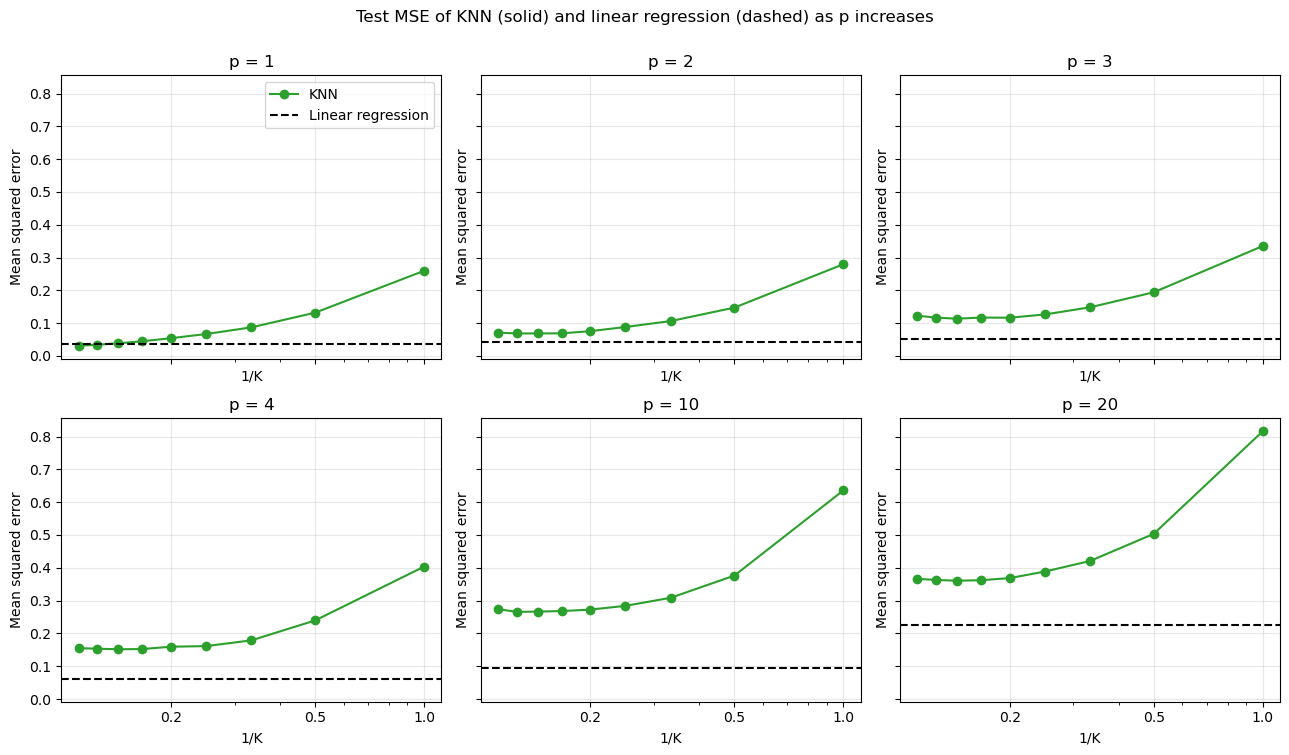

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5), sharex=True, sharey=True)
for ax, pp in zip(axes.ravel(), puse):
    d = out_knn[out_knn['p'] == pp].sort_values('1/K')
    lm = out_lm.loc[out_lm['p'] == pp, 'MSE'].item()
    ax.plot(d['1/K'], d['MSE'], 'o-', color='tab:green', label='KNN')
    ax.axhline(lm, color='black', linestyle='--', label='Linear regression')
    ax.set_title(f'p = {pp}')
    ax.set_xlabel('1/K')
    ax.set_ylabel('Mean squared error')
    ax.set_xscale('log')
    ax.set_xticks([0.2, 0.5, 1.0])
    ax.set_xticklabels(['0.2', '0.5', '1.0'])
    ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.suptitle('Test MSE of KNN (solid) and linear regression (dashed) as p increases', y=1.0)
fig.tight_layout()
plt.show()

### Decomposition into bias$^2$ and variance for KNN

For each $p$: squared bias, variance and their sum as a function of $1/K$.
Small $K$ (right end) gives a flexible fit with low bias and high variance; large $K$ (left end) the opposite.
As $p$ grows, the noisy predictors dilute the distance measure, so the nearest neighbours in $x_1$ are no longer close and the bias grows for every $K$.

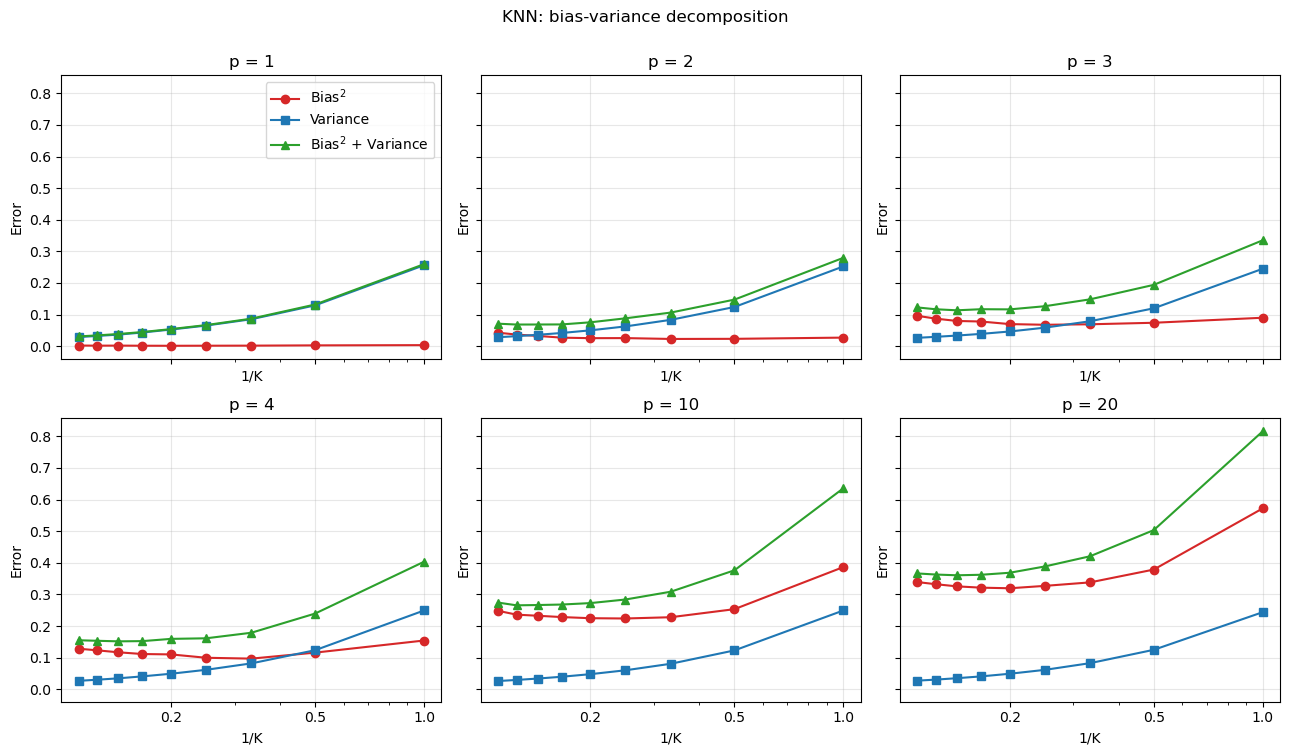

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5), sharex=True, sharey=True)
for ax, pp in zip(axes.ravel(), puse):
    d = out_knn[out_knn['p'] == pp].sort_values('1/K')
    ax.plot(d['1/K'], d['biasSQ_knn'], 'o-', color='tab:red', label='Bias$^2$')
    ax.plot(d['1/K'], d['variance_knn'], 's-', color='tab:blue', label='Variance')
    ax.plot(d['1/K'], d['MSE'], '^-', color='tab:green', label='Bias$^2$ + Variance')
    ax.set_title(f'p = {pp}')
    ax.set_xlabel('1/K')
    ax.set_ylabel('Error')
    ax.set_xscale('log')
    ax.set_xticks([0.2, 0.5, 1.0])
    ax.set_xticklabels(['0.2', '0.5', '1.0'])
    ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.suptitle('KNN: bias-variance decomposition', y=1.0)
fig.tight_layout()
plt.show()

### Decomposition for linear regression as $p$ grows

Linear regression cannot capture $\sin(2x_1)$, so its bias is essentially constant in $p$.
Each extra noisy predictor adds a coefficient that has to be estimated from 50 points, so the variance grows roughly linearly in $p$.

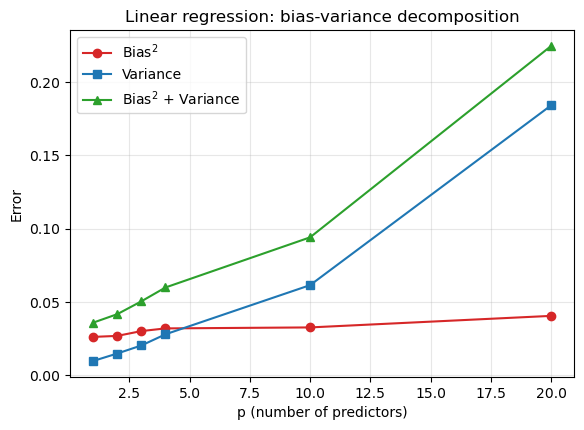

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(out_lm['p'], out_lm['biasSQ_lm'], 'o-', color='tab:red', label='Bias$^2$')
ax.plot(out_lm['p'], out_lm['variance_lm'], 's-', color='tab:blue', label='Variance')
ax.plot(out_lm['p'], out_lm['MSE'], '^-', color='tab:green', label='Bias$^2$ + Variance')
ax.set_xlabel('p (number of predictors)')
ax.set_ylabel('Error')
ax.set_title('Linear regression: bias-variance decomposition')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

### Discussion

*(Write your analysis here. Points to address:)*

- **KNN, effect of $K$:** how bias and variance move with $1/K$ and where the minimum MSE sits for each $p$.
- **KNN, effect of $p$:** the curse of dimensionality. Why the MSE for every $K$ increases with $p$, even though only $x_1$ matters.
- **Linear regression:** why bias barely changes with $p$ while variance increases. Why it is nevertheless the better model for large $p$ here.
- **Comparison:** for which $p$ KNN beats linear regression, and how this matches FIGURE 3.20 in the book.

---
## Exercises from the reference book (coding parts)

Datasets are loaded with `ISLP.load_data`. Conceptual exercises (Ch. 2: 1, 3; Ch. 3: 1, 5) go in the separate PDF.

### Chapter 2, Exercise 8 – `College`

In [8]:
College = load_data('College')
College.head()

,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
0,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
1,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
2,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
3,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
4,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15


In [9]:
# (b) summary
College.describe()

,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
count,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.00000
mean,3001.638353,2018.804376,779.972973,27.558559,55.796654,3699.907336,855.298584,10440.669241,4357.526384,549.380952,1340.642214,72.660232,79.702703,14.089704,22.743887,9660.171171,65.46332
std,3870.201484,2451.113971,929.176190,17.640364,19.804778,4850.420531,1522.431887,4023.016484,1096.696416,165.105360,677.071454,16.328155,14.722359,3.958349,12.391801,5221.768440,17.17771
min,81.000000,72.000000,35.000000,1.000000,9.000000,139.000000,1.000000,2340.000000,1780.000000,96.000000,250.000000,8.000000,24.000000,2.500000,0.000000,3186.000000,10.00000
25%,776.000000,604.000000,242.000000,15.000000,41.000000,992.000000,95.000000,7320.000000,3597.000000,470.000000,850.000000,62.000000,71.000000,11.500000,13.000000,6751.000000,53.00000
50%,1558.000000,1110.000000,434.000000,23.000000,54.000000,1707.000000,353.000000,9990.000000,4200.000000,500.000000,1200.000000,75.000000,82.000000,13.600000,21.000000,8377.000000,65.00000
75%,3624.000000,2424.000000,902.000000,35.000000,69.000000,4005.000000,967.000000,12925.000000,5050.000000,600.000000,1700.000000,85.000000,92.000000,16.500000,31.000000,10830.000000,78.00000
max,48094.000000,26330.000000,6392.000000,96.000000,100.000000,31643.000000,21836.000000,21700.000000,8124.000000,2340.000000,6800.000000,103.000000,100.000000,39.800000,64.000000,56233.000000,118.00000


In [10]:
# (c) i. scatterplot matrix of the first columns
# (c) ii. boxplots of Outstate versus Private
# (c) iii. create Elite (Top10perc > 50) and boxplots of Outstate versus Elite
# (c) iv. histograms with differing numbers of bins
# (c) v. continue exploring

### Chapter 2, Exercise 10 – `Boston`

In [11]:
Boston = load_data('Boston')
print(Boston.shape)
Boston.head()

(506, 13)


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


In [12]:
# (b) pairwise scatterplots
# (c) predictors associated with per capita crime rate
# (d) high crim / tax / ptratio suburbs, range of each predictor
# (e) suburbs bounding the Charles river
# (f) median pupil-teacher ratio
# (g) suburb with lowest medv
# (h) suburbs averaging more than seven / eight rooms per dwelling

### Chapter 3, Exercise 8 – simple linear regression on `Auto`

In [13]:
Auto = load_data('Auto')
Auto.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
name,,,,,,,,
chevrolet chevelle malibu,18.0,8,307.0,130,3504,12.0,70,1
buick skylark 320,15.0,8,350.0,165,3693,11.5,70,1
plymouth satellite,18.0,8,318.0,150,3436,11.0,70,1
amc rebel sst,16.0,8,304.0,150,3433,12.0,70,1
ford torino,17.0,8,302.0,140,3449,10.5,70,1


In [14]:
import statsmodels.api as sm
# (a) mpg ~ horsepower
# (b) plot response and predictor with the least squares line
# (c) diagnostic plots

### Chapter 3, Exercise 9 – multiple linear regression on `Auto`

In [15]:
# (a) scatterplot matrix
# (b) correlation matrix (excluding name)
# (c) mpg ~ all other variables except name
# (d) diagnostic plots
# (e) interaction effects
# (f) transformations: log(X), sqrt(X), X^2